In [4]:
#Step 1:

# Libraries Imported

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
#Load Dataset: Titanic Dataset

df = pd.read_csv("Titanic-Dataset.csv")

In [6]:
#Display dataset information

print("Dataset Name: Titanic Dataset")
print("Source: Kaggele")
print("File Type: CSV")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Name: Titanic Dataset
Source: Kaggele
File Type: CSV
Number of Rows: 891
Number of Columns: 10


In [7]:
# Step 2:

#Display the first five rows
df.head()


,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,C,PC 17599,71.2833,C85,2
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,S,113803,53.1000,C123,4
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5


In [8]:
#Display the last five rows
df.tail()


,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId
886,"Montvila, Rev. Juozas",male,27.0,0,0,S,211536,13.00,NaN,887
887,"Graham, Miss. Margaret Edith",female,19.0,0,0,S,112053,30.00,B42,888
888,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,S,W./C. 6607,23.45,NaN,889
889,"Behr, Mr. Karl Howell",male,26.0,0,0,C,111369,30.00,C148,890
890,"Dooley, Mr. Patrick",male,32.0,0,0,Q,370376,7.75,NaN,891


In [9]:
#Display column names
print(df.columns)


Index(['Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Embarked', 'Ticket', 'Fare',
       'Cabin', 'PassengerId'],
      dtype='object')


In [10]:
#Display data types and information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         891 non-null    object 
 1   Sex          891 non-null    object 
 2   Age          714 non-null    float64
 3   SibSp        891 non-null    int64  
 4   Parch        891 non-null    int64  
 5   Embarked     889 non-null    object 
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Cabin        204 non-null    object 
 9   PassengerId  891 non-null    int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 69.7+ KB


In [11]:
#Step 3:

#Separate numerical and categorical columns
numeric_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(numeric_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
Index(['Age', 'SibSp', 'Parch', 'Fare', 'PassengerId'], dtype='object')

Categorical Columns:
Index(['Name', 'Sex', 'Embarked', 'Ticket', 'Cabin'], dtype='object')


In [12]:
#Display numerical summary statistics
df.describe()

,Age,SibSp,Parch,Fare,PassengerId
count,714.000000,891.000000,891.000000,891.000000,891.000000
mean,29.699118,0.523008,0.381594,32.204208,446.000000
std,14.526497,1.102743,0.806057,49.693429,257.353842
min,0.420000,0.000000,0.000000,0.000000,1.000000
25%,20.125000,0.000000,0.000000,7.910400,223.500000
50%,28.000000,0.000000,0.000000,14.454200,446.000000
75%,38.000000,1.000000,0.000000,31.000000,668.500000
max,80.000000,8.000000,6.000000,512.329200,891.000000


In [13]:
#Identify target column
print("Possible Target Column: Survived")

Possible Target Column: Survived


In [14]:
#Check unique values
for col in categorical_cols:
    print(col, ":", df[col].nunique())

Name : 891
Sex : 2
Embarked : 3
Ticket : 681
Cabin : 147


In [15]:
#Step 4:

#Check missing values
df.isnull().sum()

,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Embarked,2
Ticket,0
Fare,0
Cabin,687
PassengerId,0


In [16]:
#Calculate missing-value percentages
missing_count = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage': missing_percentage
})

display(missing_data)

,Missing Values,Percentage
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Embarked,2,0.224467
Ticket,0,0.000000
Fare,0,0.000000
Cabin,687,77.104377
PassengerId,0,0.000000


In [17]:
#Identify columns without missing values
print("Columns without missing values:")

print(df.columns[df.isnull().sum() == 0].tolist())

Columns without missing values:
['Name', 'Sex', 'SibSp', 'Parch', 'Ticket', 'Fare', 'PassengerId']


In [18]:
#Step 5 :

#Create a copy
df_clean = df.copy()

In [19]:
#Fill missing numerical values using the median
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

In [20]:
#Fill missing categorical values using mode
df_clean['Embarked'] = df_clean['Embarked'].fillna(
    df_clean['Embarked'].mode()[0]
)

In [21]:
#Remove Cabin column
df_clean.drop('Cabin', axis=1, inplace=True)

In [22]:
#Verify missing values again
print(df_clean.isnull().sum())

Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Embarked       0
Ticket         0
Fare           0
PassengerId    0
dtype: int64


In [23]:
#Step 6:

#Find duplicate records
print("Duplicate Rows:", df_clean.duplicated().sum())

Duplicate Rows: 0


In [24]:
#Check category labels
print("Sex Categories:")
print(df_clean['Sex'].unique())

print("\nEmbarked Categories:")
print(df_clean['Embarked'].unique())

Sex Categories:
['male' 'female']

Embarked Categories:
['S' 'C' 'Q']


In [25]:
#Remove extra spaces and standardise category labels
df_clean['Sex'] = df_clean['Sex'].str.strip().str.title()

df_clean['Embarked'] = df_clean['Embarked'].str.strip().str.title()

In [26]:
#Verify duplicates again
print("Duplicates after cleaning:", df_clean.duplicated().sum())

Duplicates after cleaning: 0


In [27]:
#Step 7:

#Numerical summary
df_clean.describe()

,Age,SibSp,Parch,Fare,PassengerId
count,891.000000,891.000000,891.000000,891.000000,891.000000
mean,29.361582,0.523008,0.381594,32.204208,446.000000
std,13.019697,1.102743,0.806057,49.693429,257.353842
min,0.420000,0.000000,0.000000,0.000000,1.000000
25%,22.000000,0.000000,0.000000,7.910400,223.500000
50%,28.000000,0.000000,0.000000,14.454200,446.000000
75%,35.000000,1.000000,0.000000,31.000000,668.500000
max,80.000000,8.000000,6.000000,512.329200,891.000000


In [28]:
#Frequency count of categorical data

print("Sex Frequency:")
print(df_clean['Sex'].value_counts())

print("\nEmbarked Frequency:")
print(df_clean['Embarked'].value_counts())

print("\nSibSp Frequency:")
print(df_clean['SibSp'].value_counts())

Sex Frequency:
Sex
Male      577
Female    314
Name: count, dtype: int64

Embarked Frequency:
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

SibSp Frequency:
SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64


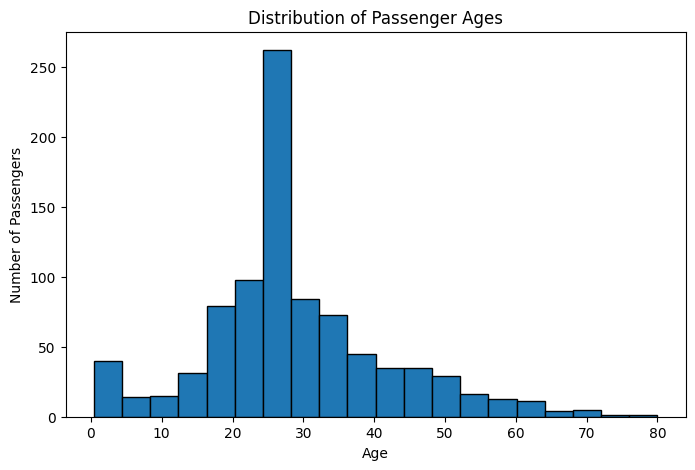

In [29]:
#Histogram
plt.figure(figsize=(8,5))

plt.hist(df_clean['Age'], bins=20, edgecolor='black')

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

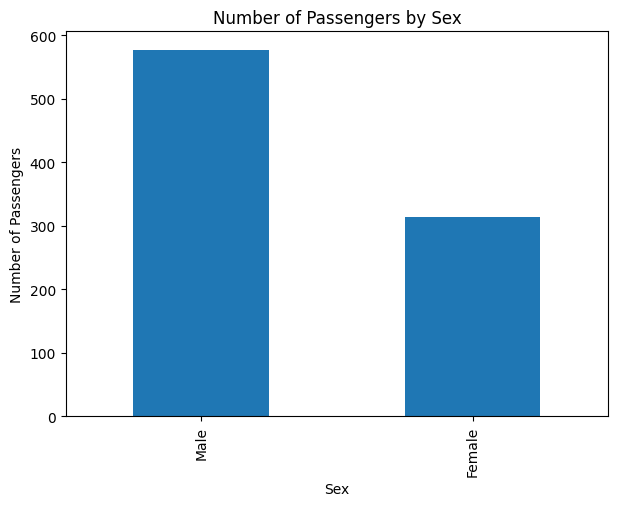

In [30]:
#Bar chart
plt.figure(figsize=(7,5))

df_clean['Sex'].value_counts().plot(kind='bar')

plt.title("Number of Passengers by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")

plt.show()

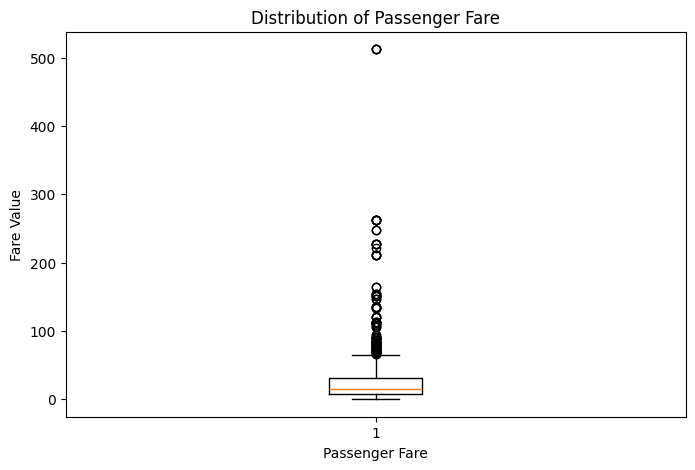

In [31]:
#Box plot
plt.figure(figsize=(8,5))

plt.boxplot(df_clean['Fare'].dropna())

plt.title("Distribution of Passenger Fare")
plt.xlabel("Passenger Fare")
plt.ylabel("Fare Value")

plt.show()

In [32]:
#Step 8:

#Encode categorical features
df_encoded = pd.get_dummies(
    df_clean,
    columns=['Sex', 'Embarked'],
    dtype=int
)

df_encoded.head()

,Name,Age,SibSp,Parch,Ticket,Fare,PassengerId,Sex_Female,Sex_Male,Embarked_C,Embarked_Q,Embarked_S
0,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,1,0,1,0,0,1
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,2,1,0,1,0,0
2,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,3,1,0,0,0,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,4,1,0,0,0,1
4,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,5,0,1,0,0,1


In [33]:
#Step 9:

#Scale numerical features
from sklearn.preprocessing import MinMaxScaler

scale_cols = ['Age', 'SibSp', 'Parch', 'Fare']

scaler = MinMaxScaler()

df_encoded[scale_cols] = scaler.fit_transform(
    df_encoded[scale_cols]
)

df_encoded.head()

,Name,Age,SibSp,Parch,Ticket,Fare,PassengerId,Sex_Female,Sex_Male,Embarked_C,Embarked_Q,Embarked_S
0,"Braund, Mr. Owen Harris",0.271174,0.125,0.0,A/5 21171,0.014151,1,0,1,0,0,1
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0.472229,0.125,0.0,PC 17599,0.139136,2,1,0,1,0,0
2,"Heikkinen, Miss. Laina",0.321438,0.000,0.0,STON/O2. 3101282,0.015469,3,1,0,0,0,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0.434531,0.125,0.0,113803,0.103644,4,1,0,0,0,1
4,"Allen, Mr. William Henry",0.434531,0.000,0.0,373450,0.015713,5,0,1,0,0,1


In [34]:
#Step 10:

#Save prepared dataset
print("Final Shape:", df_encoded.shape)

print("Missing Values:", df_encoded.isnull().sum().sum())

print("Duplicate Rows:", df_encoded.duplicated().sum())

Final Shape: (891, 12)
Missing Values: 0
Duplicate Rows: 0


In [35]:

df_encoded.to_csv("titanic_prepared.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
